# Retrievals in LangChain

https://www.geeksforgeeks.org/artificial-intelligence/retrieval-in-langchain/


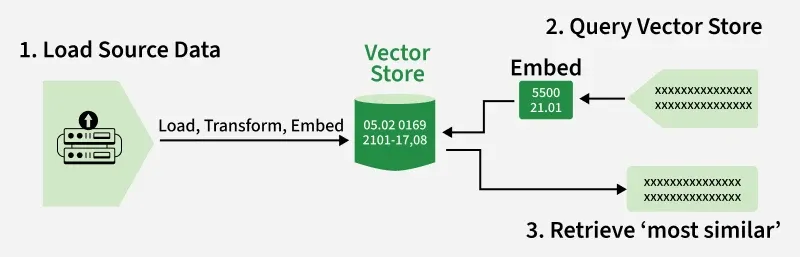

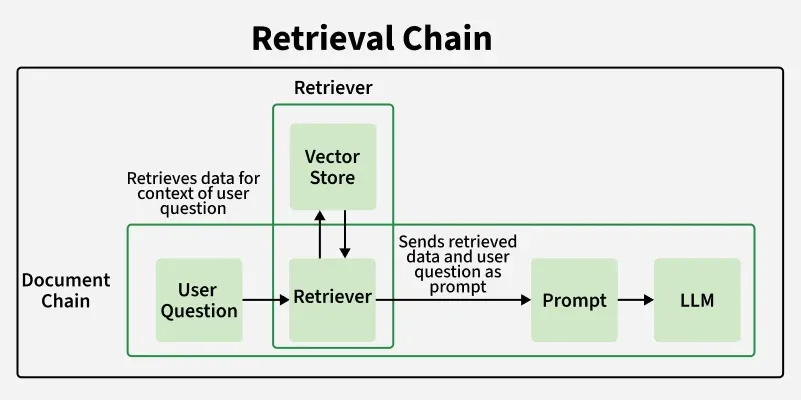

# Import Libraries

In [5]:
import os
import dotenv
from openai import OpenAI

from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# Environment Setup

In [2]:
dotenv.load_dotenv()

True

# Indexing phase (offline, done once)

In [3]:
loader = WebBaseLoader("https://lilianweng.github.io/posts/2023-06-23-agent/")
docs = loader.load()

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
all_splits = text_splitter.split_documents(docs)

vectorstore = Chroma.from_documents(
    documents=all_splits,
    embedding=OpenAIEmbeddings(),
    persist_directory="./chroma_db2"  
)

# : Retrieval and generation phase (runtime)

In [6]:
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})

llm = ChatOpenAI(model="gpt-4o", temperature=0)

system_template = (
    "Answer the user's question using the context below.\n"
    "If the context does not provide the answer, reply with \"I don't know.\"\n"
    "<context>\n"
    "{context}\n"
    "</context>\n"
)

qa_prompt = ChatPromptTemplate.from_messages([
    ("system", system_template),
    ("human", "{question}")
])


def format_docs(docs):
    """검색된 Document 리스트를 하나의 문자열로 합칩니다."""
    return "\n\n".join(doc.page_content for doc in docs)


# LCEL 파이프라인: retriever -> prompt -> llm -> parser
rag_chain = (
    {
        "context": retriever | format_docs,
        "question": RunnablePassthrough(),
    }
    | qa_prompt
    | llm
    | StrOutputParser()
)

#  Run queries

In [10]:
query = "What is the key idea of the paper?"
response =  rag_chain.invoke(query)

print("\nUser Query:", query)
print("Answer:", response)


User Query: What is the key idea of the paper?
Answer: The key idea of the paper is that any algorithm generating a set of learning histories can be distilled into a neural network through behavioral cloning over actions. The history data is generated by a set of source policies, each trained for a specific task. During training, a random task is sampled, and a subsequence of multi-episode history is used for training, making the learned policy task-agnostic. The model requires multi-episodic contexts of 2-4 episodes to learn a near-optimal in-context RL algorithm, with the emergence of in-context RL requiring a long enough context.
